In [1]:
import multiprocessing as mp
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import scvelo
import torch
import yaml
from scipy import stats
from tqdm import tqdm
import velotest
from velotest.hypothesis_testing import run_hypothesis_test_on
from velotest.neighbors import find_neighbors_in_direction_of_velocity, find_neighbors

In [2]:
datasets = {
        "Pancreas_dynamical": "../configs/pancreas_dynamic.yaml",
        "Pancreas_stochastic": "../configs/pancreas_stochastic.yaml",
        "Dentate_gyrus": "../configs/dentategyrus.yaml",
        "Gastrulation_erythroid": "../configs/gastrulation.yaml",
        "Bone_marrow": "../configs/bonemarrow.yaml",
        "PBMC": "../configs/pbmc.yaml",
        "Covid": "../configs/covid.yaml",
        "Retinal_development": "../configs/retinal_development.yaml",
        "Human_HSC": "../configs/humanHSC.yaml",
        "Intestinal_development": "../configs/noEmbedding/intestinal_organoids.yaml",
        "Hindbrain_mouse": "../configs/noEmbedding/hindbrain.yaml",
        "Oligodendrocyte_mouse": "../configs/noEmbedding/oligodendrocyte.yaml",
        "Bone_marrow_mouse": "../configs/noEmbedding/mouse_bonemarrow.yaml",
        "Cerebral_cortex_human": "../configs/noEmbedding/human_cerebral.yaml",
        "Hematopoiesis_mouse": "../configs/noEmbedding/mouse_hema.yaml",
        "Spermatogenisis": "../configs/noEmbedding/spermatogenesis.yaml",
        "Old_brain": "../configs/noEmbedding/old_brain.yaml",
        "Prefrontal_cortex": "../configs/noEmbedding/pfc.yaml",
        "Intestinal_organoids":"../configs/noEmbedding/GSE128365.yaml"
    }

x = {}
for name, path in datasets.items():
    with open(path, "r") as f:
            config = yaml.safe_load(f)
   
    adata = sc.read(config["path"]) 
    x[name] = adata.n_obs
    print(f"{name}: {adata.n_obs} cells; {np.sum(adata.var.velocity_genes)} velocity genes")

Pancreas_dynamical: 3696 cells; 1027 velocity genes
Pancreas_stochastic: 3696 cells; 1038 velocity genes
Dentate_gyrus: 2930 cells; 557 velocity genes
Gastrulation_erythroid: 9815 cells; 488 velocity genes
Bone_marrow: 5780 cells; 451 velocity genes
PBMC: 65877 cells; 12 velocity genes
Covid: 3076 cells; 126 velocity genes
Retinal_development: 2726 cells; 677 velocity genes
Human_HSC: 11605 cells; 328 velocity genes
Intestinal_development: 5422 cells; 386 velocity genes
Hindbrain_mouse: 13501 cells; 283 velocity genes
Oligodendrocyte_mouse: 36146 cells; 384 velocity genes
Bone_marrow_mouse: 2600 cells; 592 velocity genes
Cerebral_cortex_human: 4693 cells; 351 velocity genes
Hematopoiesis_mouse: 1772 cells; 1218 velocity genes
Spermatogenisis: 1829 cells; 299 velocity genes
Old_brain: 1823 cells; 1302 velocity genes
Prefrontal_cortex: 1267 cells; 1232 velocity genes
Intestinal_organoids: 3831 cells; 157 velocity genes


## Plot the general differences tSNE, UMAP, VeloViz

computing velocity embedding
    finished (0:00:00) --> added
    'velocity_pca', embedded velocity vectors (adata.obsm)
Dropping all the genes which are not velocity genes. 1027 genes left.
Number of workers:  9
Runnining with new modification


100%|██████████| 3696/3696 [00:24<00:00, 153.67it/s]


computing velocity embedding
    finished (0:00:00) --> added
    'velocity_pca', embedded velocity vectors (adata.obsm)
Dropping all the genes which are not velocity genes. 1038 genes left.
Number of workers:  9
Runnining with new modification


100%|██████████| 3696/3696 [00:24<00:00, 153.62it/s]


computing velocity embedding
    finished (0:00:00) --> added
    'velocity_pca', embedded velocity vectors (adata.obsm)
Dropping all the genes which are not velocity genes. 557 genes left.
Number of workers:  9
Runnining with new modification


...

100%|██████████| 1823/1823 [00:07<00:00, 257.47it/s]


computing velocity embedding
    finished (0:00:00) --> added
    'velocity_pca', embedded velocity vectors (adata.obsm)
Dropping all the genes which are not velocity genes. 1232 genes left.
Number of workers:  9
Runnining with new modification


100%|██████████| 1267/1267 [00:05<00:00, 231.81it/s]


computing velocity embedding
    finished (0:00:00) --> added
    'velocity_pca', embedded velocity vectors (adata.obsm)
Dropping all the genes which are not velocity genes. 157 genes left.
Number of workers:  9
Runnining with new modification


100%|██████████| 3831/3831 [00:12<00:00, 310.70it/s]


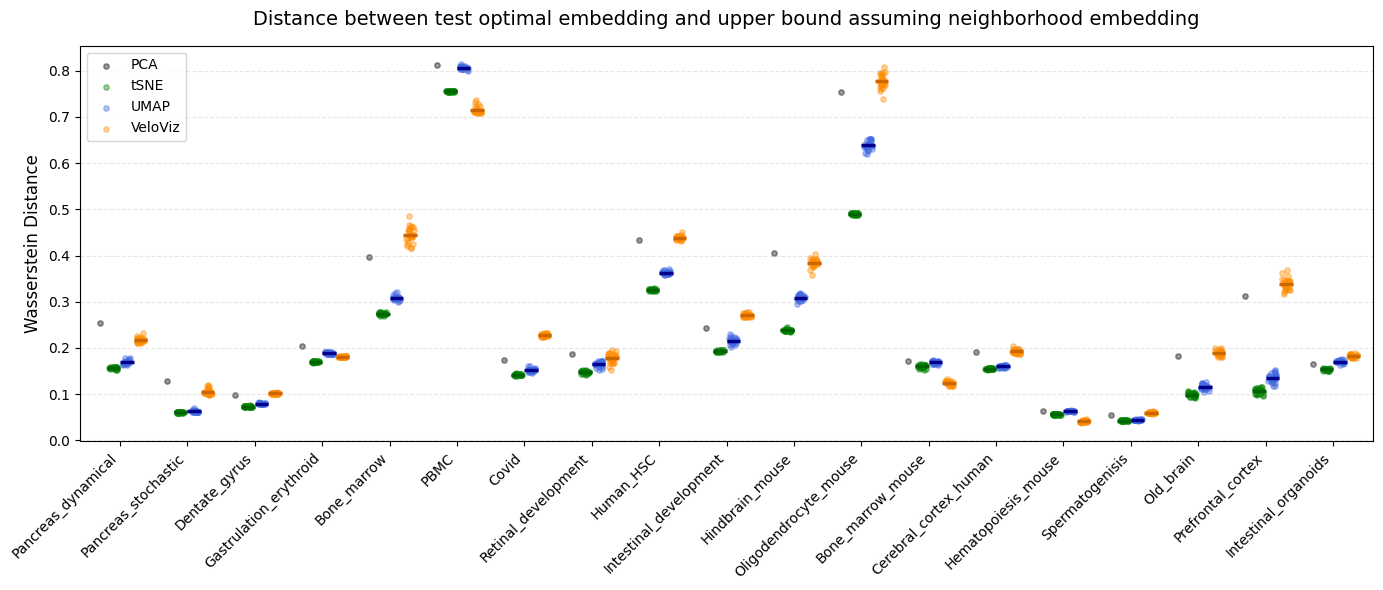

In [7]:
tsne_values = pd.read_csv("/mnt/volume/Johanna_Velotest/results/distances/0504_Was_all_tSNE.csv")
umap_values = pd.read_csv("/mnt/volume/Johanna_Velotest/results/distances/0427_Was_all_UMAP.csv")
veloviz_values = pd.read_csv("/mnt/volume/Johanna_Velotest/results/distances/0519_Was_all_Veloviz.csv")

plotset= {}

for name, path in datasets.items():
    with open(path, "r") as f:
        config = yaml.safe_load(f)

    adata = sc.read(config['path'])
    scvelo.tl.velocity_embedding(adata, basis='pca')
    neighbors = config['number_neighbors_to_sample_from']
    uncorrected_p_values, h0_rejected, debug_dict = run_hypothesis_test_on(adata, basis='pca', number_neighbors_to_sample_from=neighbors, null_distribution="velocities-explicit", cosine_empty_neighborhood=None, correction="bonferroni", restrict_to_velocity_genes=True, exclusion_degree=10)
    statistics = debug_dict['statistics']
    best_value = [statistics.get_max_value(offset=True)[1] for statistics in statistics if statistics is not None]
    upper = adata.obsm['upper_max_neighbors']
    

    plotset[name] = {
        'pca': stats.wasserstein_distance(best_value, upper),
        'tsne': tsne_values[name].values,
        'umap': umap_values[name].values,
        'veloviz': veloviz_values[name].values
    }


fig, ax = plt.subplots(figsize=(14, 6))

def add_jitter(x_base, arr, width=0.06):
    return x_base + np.random.uniform(-width, width, size=len(arr))

offsets = {'pca': -0.3, 'tsne': -0.1, 'umap': 0.1, 'veloviz': 0.3}
colors = {'pca': 'black', 'tsne': 'green', 'umap': 'royalblue', 'veloviz': 'darkorange'}

# Dictionary to catch one of each handle for a clean legend
legend_elements = {}

for i, name in enumerate(plotset):
    d = plotset[name]

    # Plot PCA
    x_pca = i + offsets['pca']
    h_pca = ax.scatter(x_pca, d['pca'], color=colors['pca'], alpha=0.4, s=15)
    if 'PCA' not in legend_elements: 
        legend_elements['PCA'] = h_pca

    # Plot tSNE
    x_tsne = i + offsets['tsne']
    h_tsne = ax.scatter(add_jitter(x_tsne, d['tsne']), d['tsne'], color=colors['tsne'], alpha=0.4, s=15)
    h_mean = ax.hlines(np.mean(d['tsne']), x_tsne-0.1, x_tsne+0.1, color='darkgreen', linewidth=2.5)
    if 'tSNE Random Init' not in legend_elements: 
        legend_elements['tSNE'] = h_tsne

    # Plot UMAP 
    x_umap = i + offsets['umap']
    h_umap = ax.scatter(add_jitter(x_umap, d['umap']), d['umap'], color=colors['umap'], alpha=0.4, s=15)
    ax.hlines(np.mean(d['umap']), x_umap-0.1, x_umap+0.1, color='darkblue', linewidth=2.5)
    if 'UMAP Random Init' not in legend_elements: 
        legend_elements['UMAP'] = h_umap

    # Plot veloviz
    x_velo = i + offsets['veloviz']
    h_velo = ax.scatter(add_jitter(x_velo, d['veloviz']), d['veloviz'], color=colors['veloviz'], alpha=0.4, s=15)
    ax.hlines(np.mean(d['veloviz']), x_velo-0.1, x_velo+0.1, color='#cc6600', linewidth=2.5)
    if 'VeloViz' not in legend_elements: 
        legend_elements['VeloViz'] = h_velo


# Set x-ticks exactly at the integer positions for the datasets
ax.set_xticks(range(len(plotset)))
ax.set_xticklabels(plotset, rotation=45, ha='right', fontsize=10)
ax.set_xlim(-0.6, len(plotset) - 0.4)

ax.grid(True, axis='y', alpha=0.3, linestyle='--')
ax.set_ylabel("Wasserstein Distance", fontsize=12)
ax.set_title("Distance between test optimal embedding and upper bound assuming neighborhood embedding", fontsize=14, pad=15)

# Build custom legend using our deduplicated handles
# Placed slightly outside the plot area to prevent overlapping the 8 datasets
ax.legend(legend_elements.values(), legend_elements.keys(), 
        loc='upper left')

plt.tight_layout()
#plt.savefig("results/Wasserstein_UMAP_TSNE.pdf", transparent=True)
plt.show()

In [3]:
tsne_values = pd.read_csv("/mnt/volume/Johanna_Velotest/results/distances/0504_Was_all_tSNE.csv")
umap_values = pd.read_csv("/mnt/volume/Johanna_Velotest/results/distances/0427_Was_all_UMAP.csv")
veloviz_values = pd.read_csv("/mnt/volume/Johanna_Velotest/results/distances/0519_Was_all_Veloviz.csv")
count_df = pd.DataFrame(list(x.items()), columns=['Dataset', 'CellCount'])

plotset= {}

for name, path in datasets.items():
    with open(path, "r") as f:
        config = yaml.safe_load(f)

    adata = sc.read(config['path'])
    scvelo.tl.velocity_embedding(adata, basis='pca')
    neighbors = config['number_neighbors_to_sample_from']
    uncorrected_p_values, h0_rejected, debug_dict = run_hypothesis_test_on(adata, basis='pca', number_neighbors_to_sample_from=neighbors, null_distribution="velocities-explicit", cosine_empty_neighborhood=None, correction="bonferroni", restrict_to_velocity_genes=True, exclusion_degree=10)
    statistics = debug_dict['statistics']
    best_value = [statistics.get_max_value(offset=True)[1] for statistics in statistics if statistics is not None]
    upper = adata.obsm['upper_max_neighbors']
    

    plotset[name] = {
        'pca': stats.wasserstein_distance(best_value, upper),
        'tsne': tsne_values[name].values,
        'umap': umap_values[name].values,
        'veloviz': veloviz_values[name].values
    }

sorted_dataset_names = count_df.sort_values(by='CellCount')['Dataset'].tolist()

fig, ax = plt.subplots(figsize=(14, 6))

def add_jitter(x_base, arr, width=0.06):
    return x_base + np.random.uniform(-width, width, size=len(arr))

offsets = {'pca': -0.3, 'tsne': -0.1, 'umap': 0.1, 'veloviz': 0.3}
colors = {'pca': 'black', 'tsne': 'green', 'umap': 'royalblue', 'veloviz': 'darkorange'}

# Dictionary to catch one of each handle for a clean legend
legend_elements = {}

for i, name in enumerate(sorted_dataset_names):
    d = plotset[name]

    # Plot PCA
    x_pca = i + offsets['pca']
    h_pca = ax.scatter(x_pca, d['pca'], color=colors['pca'], alpha=0.4, s=15)
    if 'PCA' not in legend_elements: 
        legend_elements['PCA'] = h_pca

    # Plot tSNE
    x_tsne = i + offsets['tsne']
    h_tsne = ax.scatter(add_jitter(x_tsne, d['tsne']), d['tsne'], color=colors['tsne'], alpha=0.4, s=15)
    h_mean = ax.hlines(np.mean(d['tsne']), x_tsne-0.1, x_tsne+0.1, color='darkgreen', linewidth=2.5)
    if 'tSNE Random Init' not in legend_elements: 
        legend_elements['tSNE'] = h_tsne

    # Plot UMAP 
    x_umap = i + offsets['umap']
    h_umap = ax.scatter(add_jitter(x_umap, d['umap']), d['umap'], color=colors['umap'], alpha=0.4, s=15)
    ax.hlines(np.mean(d['umap']), x_umap-0.1, x_umap+0.1, color='darkblue', linewidth=2.5)
    if 'UMAP Random Init' not in legend_elements: 
        legend_elements['UMAP'] = h_umap

    # Plot veloviz
    x_velo = i + offsets['veloviz']
    h_velo = ax.scatter(add_jitter(x_velo, d['veloviz']), d['veloviz'], color=colors['veloviz'], alpha=0.4, s=15)
    ax.hlines(np.mean(d['veloviz']), x_velo-0.1, x_velo+0.1, color='#cc6600', linewidth=2.5)
    if 'VeloViz' not in legend_elements: 
        legend_elements['VeloViz'] = h_velo


# Set x-ticks exactly at the integer positions for the datasets
ax.set_xticks(range(len(sorted_dataset_names)))
ax.set_xticklabels(sorted_dataset_names, rotation=45, ha='right', fontsize=10)
ax.set_xlim(-0.6, len(sorted_dataset_names) - 0.4)

ax.grid(True, axis='y', alpha=0.3, linestyle='--')
ax.set_ylabel("Wasserstein Distance", fontsize=12)
ax.set_title("Distance between test optimal embedding and upper bound assuming neighborhood embedding", fontsize=14, pad=15)

# Build custom legend using our deduplicated handles
# Placed slightly outside the plot area to prevent overlapping the 8 datasets
ax.legend(legend_elements.values(), legend_elements.keys(), 
        loc='upper left')

plt.tight_layout()
#plt.savefig("results/Wasserstein_UMAP_Neighbors.pdf", transparent=True)
plt.show()

computing velocity embedding
    finished (0:00:00) --> added
    'velocity_pca', embedded velocity vectors (adata.obsm)
Dropping all the genes which are not velocity genes. 1027 genes left.
Number of workers:  9
Runnining with new modification


100%|██████████| 3696/3696 [00:24<00:00, 152.51it/s]


computing velocity embedding
    finished (0:00:00) --> added
    'velocity_pca', embedded velocity vectors (adata.obsm)
Dropping all the genes which are not velocity genes. 1038 genes left.
Number of workers:  9
Runnining with new modification


100%|██████████| 3696/3696 [00:24<00:00, 153.07it/s]


computing velocity embedding
    finished (0:00:00) --> added
    'velocity_pca', embedded velocity vectors (adata.obsm)
Dropping all the genes which are not velocity genes. 557 genes left.
Number of workers:  9
Runnining with new modification


...

computing velocity embedding
    finished (0:00:02) --> added
    'velocity_pca', embedded velocity vectors (adata.obsm)
Dropping all the genes which are not velocity genes. 283 genes left.
Number of workers:  9
Runnining with new modification


100%|██████████| 13501/13501 [01:30<00:00, 148.38it/s]


computing velocity embedding
    finished (0:00:08) --> added
    'velocity_pca', embedded velocity vectors (adata.obsm)
Dropping all the genes which are not velocity genes. 384 genes left.
Number of workers:  9
Runnining with new modification


 62%|██████▏   | 22460/36146 [45:16<27:35,  8.27it/s]  
Process SpawnPoolWorker-101:
Process SpawnPoolWorker-108:
Process SpawnPoolWorker-102:
Traceback (most recent call last):
  File "/mnt/volume/Johanna_Velotest/enviroments/velotest_a/lib/python3.10/multiprocessing/process.py", line 314, in _bootstrap
    self.run()
  File "/mnt/volume/Johanna_Velotest/enviroments/velotest_a/lib/python3.10/multiprocessing/process.py", line 108, in run
    self._target(*self._args, **self._kwargs)
  File "/mnt/volume/Johanna_Velotest/enviroments/velotest_a/lib/python3.10/multiprocessing/pool.py", line 125, in worker
    result = (True, func(*args, **kwds))
  File "/mnt/volume/Johanna_Velotest/enviroments/velotest_a/lib/python3.10/multiprocessing/pool.py", line 48, in mapstar
    return list(map(*args))
  File "/mnt/volume/Johanna_Velotest/velocity-hypothesis-test/velotest/explicit_hypothesis_testing.py", line 275, in _worker_cell
    return compute_step_statistics(cell_idx, _WORKER_COS_SIM, _WORKER_A

KeyboardInterrupt: 

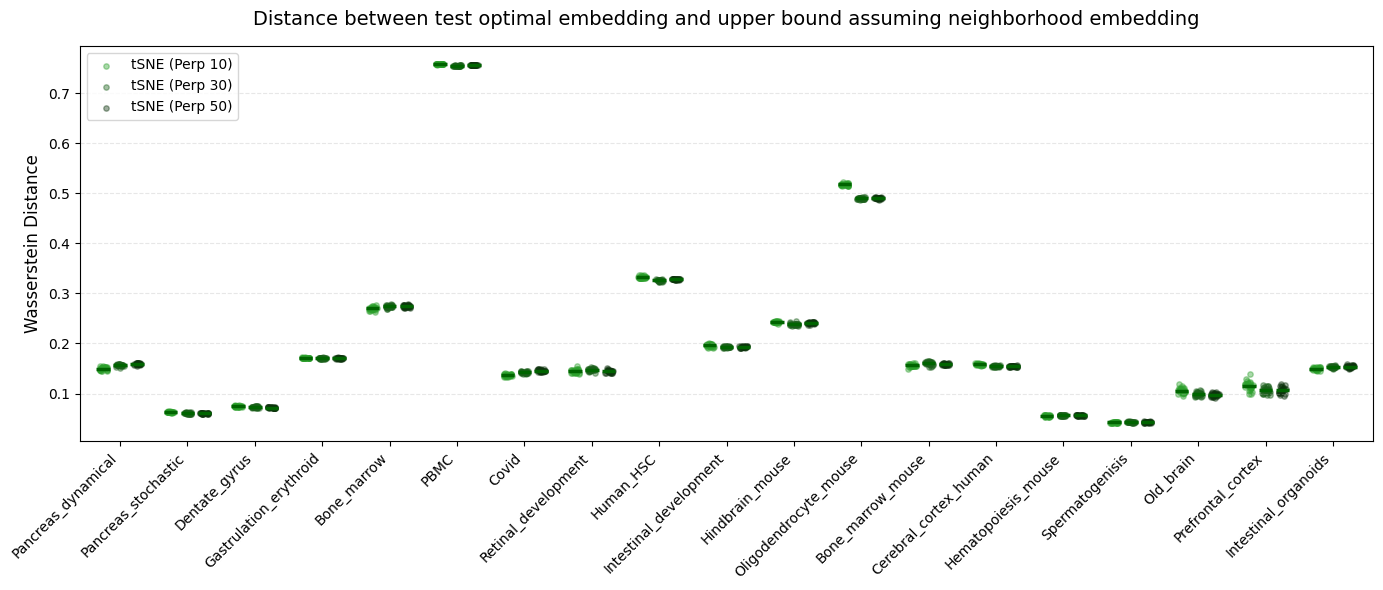

In [5]:
tsne10_values = pd.read_csv("/mnt/volume/Johanna_Velotest/results/distances/0511_Was_all_tSNE_p10.csv")
tsne30_values = pd.read_csv("/mnt/volume/Johanna_Velotest/results/distances/0504_Was_all_tSNE.csv")
tsne50_values = pd.read_csv("/mnt/volume/Johanna_Velotest/results/distances/0511_Was_all_tSNE_p50.csv")

plotset= {}

for name, path in datasets.items():
    plotset[name] = {
        'tsne_10': tsne10_values[name].values,
        'tsne_30': tsne30_values[name].values,
        'tsne_50': tsne50_values[name].values
    }


fig, ax = plt.subplots(figsize=(14, 6))

def add_jitter(x_base, arr, width=0.06):
    return x_base + np.random.uniform(-width, width, size=len(arr))

offsets = {'tsne_10': -0.25, 'tsne_30': 0.0, 'tsne_50': 0.25}
colors = {'tsne_10': '#2ca02c', 'tsne_30': '#1a5f1a', 'tsne_50': '#0d330d'}

# Dictionary to catch one of each handle for a clean legend
legend_elements = {}

for i, name in enumerate(plotset):
    d = plotset[name]

    # Plot tSNE 10
    x_tsne_10 = i + offsets['tsne_10']
    h_tsne_10 = ax.scatter(add_jitter(x_tsne_10, d['tsne_10']), d['tsne_10'], color=colors['tsne_10'], alpha=0.4, s=15)
    h_mean_10 = ax.hlines(np.mean(d['tsne_10']), x_tsne_10-0.1, x_tsne_10+0.1, color='darkgreen', linewidth=2.5)
    if 'tSNE (Perp 10)' not in legend_elements: 
        legend_elements['tSNE (Perp 10)'] = h_tsne_10


    # Plot tSNE 30
    x_tsne_30 = i + offsets['tsne_30']
    h_tsne_30 = ax.scatter(add_jitter(x_tsne_30, d['tsne_30']), d['tsne_30'], color=colors['tsne_30'], alpha=0.4, s=15)
    ax.hlines(np.mean(d['tsne_30']), x_tsne_30-0.1, x_tsne_30+0.1, color='darkgreen', linewidth=2.5)
    if 'tSNE (Perp 30)' not in legend_elements: 
        legend_elements['tSNE (Perp 30)'] = h_tsne_30

    # Plot tSNE 50
    x_tsne_50 = i + offsets['tsne_50']
    h_tsne_50 = ax.scatter(add_jitter(x_tsne_50, d['tsne_50']), d['tsne_50'], color=colors['tsne_50'], alpha=0.4, s=15)
    ax.hlines(np.mean(d['tsne_50']), x_tsne_50-0.1, x_tsne_50+0.1, color='darkgreen', linewidth=2.5)
    if 'tSNE (Perp 50)' not in legend_elements: 
        legend_elements['tSNE (Perp 50)'] = h_tsne_50


# Set x-ticks exactly at the integer positions for the datasets
ax.set_xticks(range(len(plotset)))
ax.set_xticklabels(plotset, rotation=45, ha='right', fontsize=10)
ax.set_xlim(-0.6, len(plotset) - 0.4)

ax.grid(True, axis='y', alpha=0.3, linestyle='--')
ax.set_ylabel("Wasserstein Distance", fontsize=12)
ax.set_title("Distance between test optimal embedding and upper bound assuming neighborhood embedding", fontsize=14, pad=15)

# Build custom legend using our deduplicated handles
# Placed slightly outside the plot area to prevent overlapping the 8 datasets
ax.legend(legend_elements.values(), legend_elements.keys(), 
        loc='upper left')

plt.tight_layout()
#plt.savefig("results/Wasserstein_UMAP_TSNE.pdf", transparent=True)
plt.show()

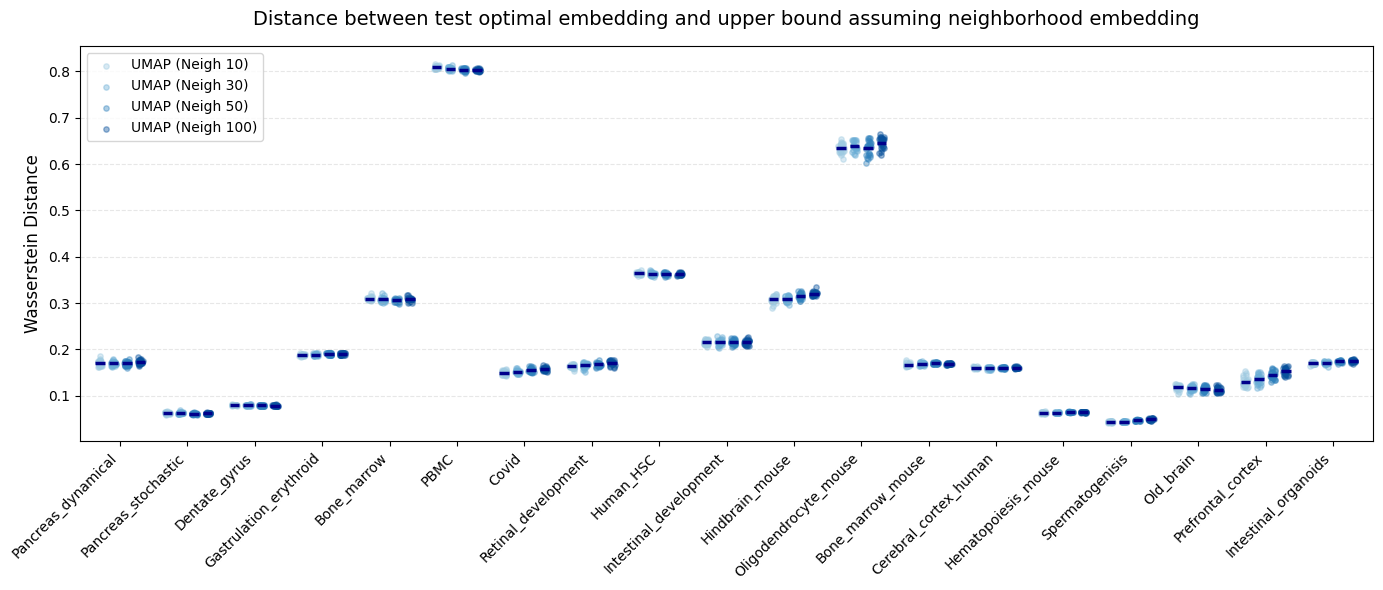

In [8]:
umap10_values = pd.read_csv("/mnt/volume/Johanna_Velotest/results/distances/0521_Was_all_UMAP_n10.csv")
umap30_values = pd.read_csv("/mnt/volume/Johanna_Velotest/results/distances/0427_Was_all_UMAP.csv")
umap50_values = pd.read_csv("/mnt/volume/Johanna_Velotest/results/distances/0525_Was_all_UMAP_n50.csv")
umap100_values = pd.read_csv("/mnt/volume/Johanna_Velotest/results/distances/0525_Was_all_UMAP_n100.csv")

plotset= {}

for name, path in datasets.items():
    plotset[name] = {
        'umap_10': umap10_values[name].values,
        'umap_30': umap30_values[name].values,
        'umap_50': umap50_values[name].values,
        'umap_100': umap100_values[name].values,
    }

fig, ax = plt.subplots(figsize=(14, 6))

def add_jitter(x_base, arr, width=0.04):
    return x_base + np.random.uniform(-width, width, size=len(arr))

offsets = {'umap_10': -0.3, 'umap_30': -0.1, 'umap_50': 0.1, 'umap_100': 0.3}
colors = {'umap_10': '#9ecae1', 'umap_30': '#6baed6', 'umap_50': '#3182bd', 'umap_100': '#08519c'}

# Dictionary to catch one of each handle for a clean legend
legend_elements = {}

for i, name in enumerate(plotset):
    d = plotset[name]

    # Plot UMAP 10
    x_umap_10 = i + offsets['umap_10']
    h_umap_10 = ax.scatter(add_jitter(x_umap_10, d['umap_10']), d['umap_10'], color=colors['umap_10'], alpha=0.4, s=15)
    h_mean_10 = ax.hlines(np.mean(d['umap_10']), x_umap_10-0.07, x_umap_10+0.07, color='darkblue', linewidth=2.5)
    if 'UMAP (Neigh 10)' not in legend_elements: 
        legend_elements['UMAP (Neigh 10)'] = h_umap_10


    # Plot UMAP 30
    x_umap_30 = i + offsets['umap_30']
    h_umap_30 = ax.scatter(add_jitter(x_umap_30, d['umap_30']), d['umap_30'], color=colors['umap_30'], alpha=0.4, s=15)
    ax.hlines(np.mean(d['umap_30']), x_umap_30-0.07, x_umap_30+0.07, color='darkblue', linewidth=2.5)
    if 'UMAP (Neigh 30)' not in legend_elements: 
        legend_elements['UMAP (Neigh 30)'] = h_umap_30

    # Plot UMAP 50
    x_umap_50 = i + offsets['umap_50']
    h_umap_50 = ax.scatter(add_jitter(x_umap_50, d['umap_50']), d['umap_50'], color=colors['umap_50'], alpha=0.4, s=15)
    ax.hlines(np.mean(d['umap_50']), x_umap_50-0.07, x_umap_50+0.07, color='darkblue', linewidth=2.5)
    if 'UMAP (Neigh 50)' not in legend_elements: 
        legend_elements['UMAP (Neigh 50)'] = h_umap_50

    # Plot UMAP 100
    x_umap_100 = i + offsets['umap_100']
    h_umap_100 = ax.scatter(add_jitter(x_umap_100, d['umap_100']), d['umap_100'], color=colors['umap_100'], alpha=0.4, s=15)
    ax.hlines(np.mean(d['umap_100']), x_umap_100-0.07, x_umap_100+0.07, color='darkblue', linewidth=2.5)
    if 'UMAP (Neigh 100)' not in legend_elements: 
        legend_elements['UMAP (Neigh 100)'] = h_umap_100


# Set x-ticks exactly at the integer positions for the datasets
ax.set_xticks(range(len(plotset)))
ax.set_xticklabels(plotset, rotation=45, ha='right', fontsize=10)
ax.set_xlim(-0.6, len(plotset) - 0.4)

ax.grid(True, axis='y', alpha=0.3, linestyle='--')
ax.set_ylabel("Wasserstein Distance", fontsize=12)
ax.set_title("Distance between test optimal embedding and upper bound assuming neighborhood embedding", fontsize=14, pad=15)

# Build custom legend using our deduplicated handles
# Placed slightly outside the plot area to prevent overlapping the 8 datasets
ax.legend(legend_elements.values(), legend_elements.keys(), 
        loc='upper left')

plt.tight_layout()
#plt.savefig("results/Wasserstein_UMAP_Neighbors.pdf", transparent=True)
plt.show()

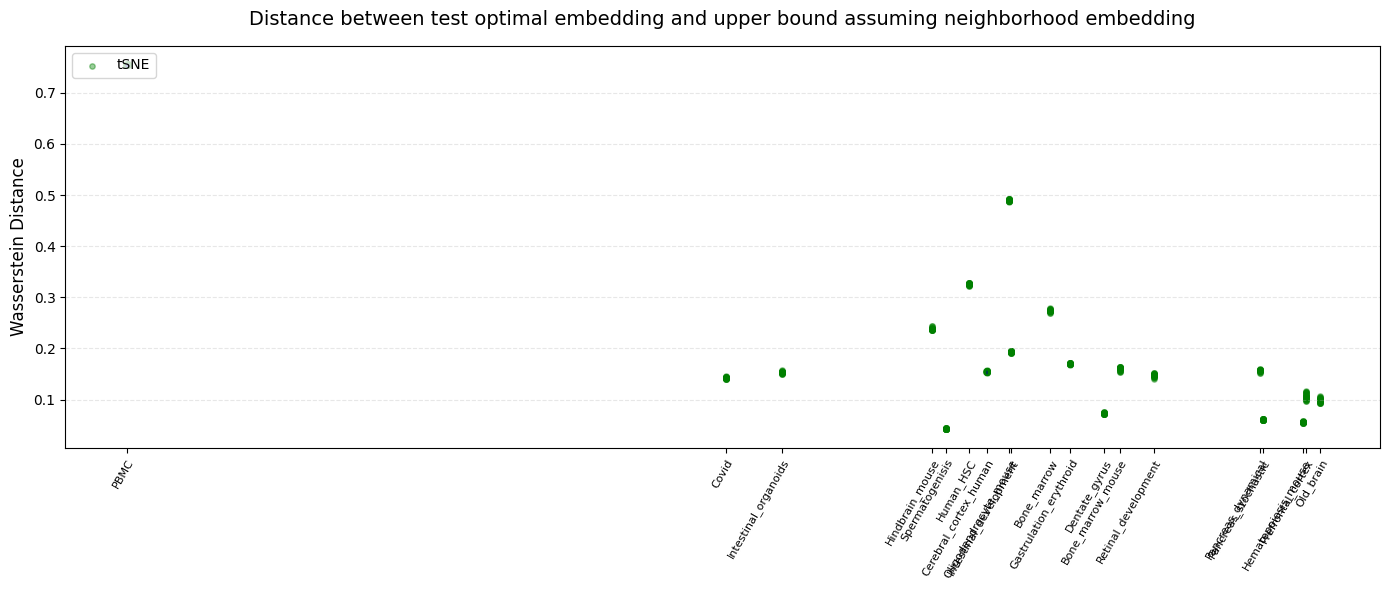

In [6]:
tsne_values = pd.read_csv("/mnt/volume/Johanna_Velotest/results/distances/0504_Was_all_tSNE.csv")
count_df = pd.DataFrame(list(x.items()), columns=['Dataset', 'CellCount'])
plotset= {}

for name, path in datasets.items():
    plotset[name] = {
        'tsne': tsne_values[name].values,
    }


fig, ax = plt.subplots(figsize=(14, 6))

def add_jitter(x_base, arr, width=0.06):
    return x_base + np.random.uniform(-width, width, size=len(arr))

offsets = {'tsne': -0.25, 'umap': 0.0, 'veloviz': 0.25}
colors = {'tsne': 'green', 'umap': 'royalblue', 'veloviz': 'darkorange'}

# Dictionary to catch one of each handle for a clean legend
legend_elements = {}

for i, name in enumerate(plotset):
    d = plotset[name]

    # Plot tSNE
    x_tsne = x[name]
    h_tsne = ax.scatter(add_jitter(x_tsne, d['tsne']), d['tsne'], color=colors['tsne'], alpha=0.4, s=15)
    h_mean = ax.hlines(np.mean(d['tsne']), x_tsne-0.1, x_tsne+0.1, color='darkblue', linewidth=2.5)
    if 'tSNE Random Init' not in legend_elements: 
        legend_elements['tSNE'] = h_tsne




ax.grid(True, axis='y', alpha=0.3, linestyle='--')
ax.set_ylabel("Wasserstein Distance", fontsize=12)
ax.set_title("Distance between test optimal embedding and upper bound assuming neighborhood embedding", fontsize=14, pad=15)

# Build custom legend using our deduplicated handles
# Placed slightly outside the plot area to prevent overlapping the 8 datasets
ax.legend(legend_elements.values(), legend_elements.keys(), 
        loc='upper left')

plt.xscale('log')

from matplotlib.ticker import ScalarFormatter, NullLocator
plt.gca().xaxis.set_major_formatter(ScalarFormatter())
plt.gca().xaxis.set_minor_locator(NullLocator())

# Label the x-axis with the specific cell count values and dataset names
plt.xticks(
    ticks=count_df['CellCount'], 
    labels=[f"{n}" for n, c in zip(count_df['Dataset'], count_df['CellCount'])],
    rotation=60, 
    ha='right',
    rotation_mode='anchor',
    fontsize=8
)
plt.tight_layout()
#plt.savefig("results/Wasserstein_UMAP_TSNE.pdf", transparent=True)
plt.show()

Pancreas_dynamical: 3696 cells; 1027 velocity genes
Pancreas_stochastic: 3696 cells; 1038 velocity genes
Dentate_gyrus: 2930 cells; 557 velocity genes
Gastrulation_erythroid: 9815 cells; 488 velocity genes
Bone_marrow: 5780 cells; 451 velocity genes
PBMC: 65877 cells; 12 velocity genes
Covid: 3076 cells; 126 velocity genes
Retinal_development: 2726 cells; 677 velocity genes
Human_HSC: 11605 cells; 328 velocity genes
Intestinal_development: 5422 cells; 386 velocity genes
Hindbrain_mouse: 13501 cells; 283 velocity genes
Oligodendrocyte_mouse: 36146 cells; 384 velocity genes
Bone_marrow_mouse: 2600 cells; 592 velocity genes
Cerebral_cortex_human: 4693 cells; 351 velocity genes
Intestinal_organoids: 3831 cells; 157 velocity genes
['PBMC', 'Covid', 'Intestinal_organoids', 'Pancreas_dynamical', 'Gastrulation_erythroid', 'Dentate_gyrus', 'Bone_marrow', 'Pancreas_stochastic', 'Retinal_development', 'Human_HSC', 'Hindbrain_mouse', 'Intestinal_development', 'Oligodendrocyte_mouse', 'Bone_marrow_

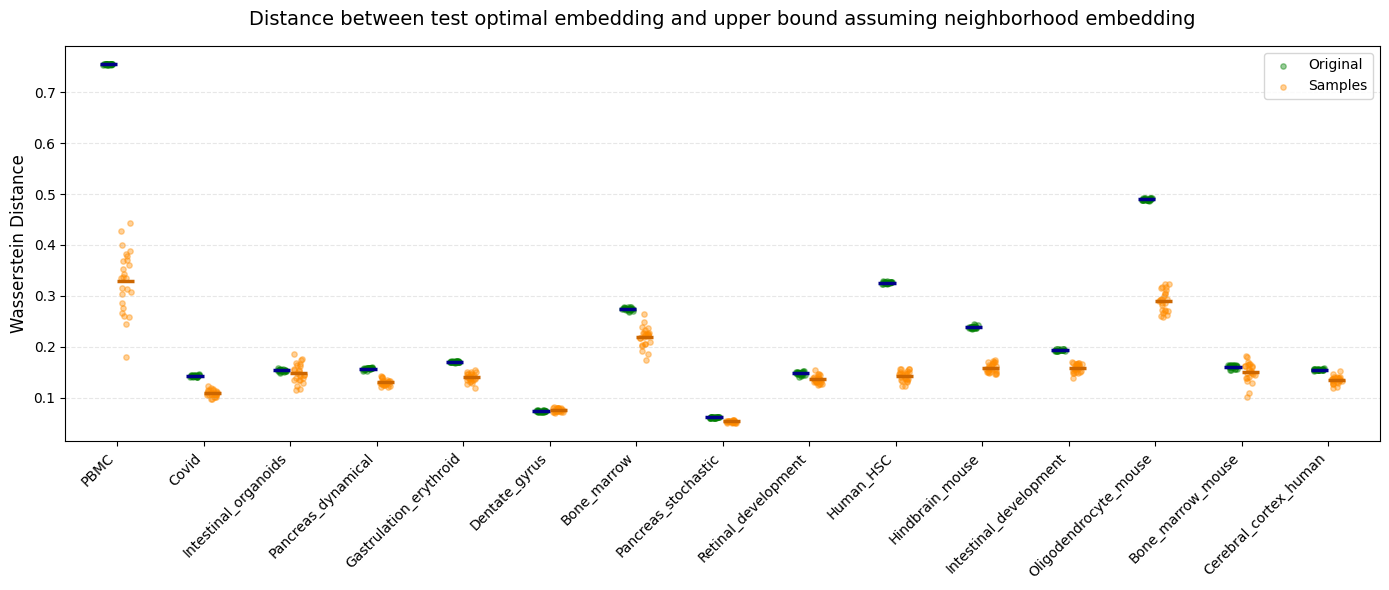

In [14]:
datasets = {
        "Pancreas_dynamical": "../configs/pancreas_dynamic.yaml",
        "Pancreas_stochastic": "../configs/pancreas_stochastic.yaml",
        "Dentate_gyrus": "../configs/dentategyrus.yaml",
        "Gastrulation_erythroid": "../configs/gastrulation.yaml",
        "Bone_marrow": "../configs/bonemarrow.yaml",
        "PBMC": "../configs/pbmc.yaml",
        "Covid": "../configs/covid.yaml",
        "Retinal_development": "../configs/retinal_development.yaml",
        "Human_HSC": "../configs/humanHSC.yaml",
        "Intestinal_development": "../configs/noEmbedding/intestinal_organoids.yaml",
        "Hindbrain_mouse": "../configs/noEmbedding/hindbrain.yaml",
        "Oligodendrocyte_mouse": "../configs/noEmbedding/oligodendrocyte.yaml",
        "Bone_marrow_mouse": "../configs/noEmbedding/mouse_bonemarrow.yaml",
        "Cerebral_cortex_human": "../configs/noEmbedding/human_cerebral.yaml",
        #"Hematopoiesis_mouse": "../configs/noEmbedding/mouse_hema.yaml",
        #"Spermatogenisis": "../configs/noEmbedding/spermatogenesis.yaml",
        #"Old_brain": "../configs/noEmbedding/old_brain.yaml",
        #"Prefrontal_cortex": "../configs/noEmbedding/pfc.yaml",
        "Intestinal_organoids":"../configs/noEmbedding/GSE128365.yaml"
    }

x = {}
for name, path in datasets.items():
    with open(path, "r") as f:
            config = yaml.safe_load(f)
   
    adata = sc.read(config["path"]) 
    N = adata.n_obs
    D = np.sum(adata.var.velocity_genes)
    x[name] = N ** ((D-2)/2)
    print(f"{name}: {adata.n_obs} cells; {np.sum(adata.var.velocity_genes)} velocity genes")

tsne_values = pd.read_csv("/mnt/volume/Johanna_Velotest/results/distances/0504_Was_all_tSNE.csv")
sampled_tsne = pd.read_csv("/mnt/volume/Johanna_Velotest/results/distances/0616_Was_all_subsampled_2000cells.csv")
count_df = pd.DataFrame(list(x.items()), columns=['Dataset', 'VelocityGenes'])
plotset= {}

for name, path in datasets.items():
    plotset[name] = {
        'tsne': tsne_values[name].values,
        'samp': sampled_tsne[name].values
    }

sorted_dataset_names = count_df.sort_values(by='VelocityGenes')['Dataset'].tolist()
print(sorted_dataset_names)

fig, ax = plt.subplots(figsize=(14, 6))

def add_jitter(x_base, arr, width=0.06):
    return x_base + np.random.uniform(-width, width, size=len(arr))

offsets = {'tsne': -0.1, 'umap': 0.0, 'samp': 0.1}
colors = {'tsne': 'green', 'umap': 'royalblue', 'samp': 'darkorange'}

# Dictionary to catch one of each handle for a clean legend
legend_elements = {}

for i, name in enumerate(sorted_dataset_names):
    d = plotset[name]

    # Plot tSNE
    x_tsne = i + offsets['tsne']
    h_tsne = ax.scatter(add_jitter(x_tsne, d['tsne']), d['tsne'], color=colors['tsne'], alpha=0.4, s=15)
    h_mean = ax.hlines(np.mean(d['tsne']), x_tsne-0.1, x_tsne+0.1, color='darkblue', linewidth=2.5)
    if 'tSNE Random Init' not in legend_elements: 
        legend_elements['Original'] = h_tsne

    # Plot sampled
    x_velo = i + offsets['samp']
    h_velo = ax.scatter(add_jitter(x_velo, d['samp']), d['samp'], color=colors['samp'], alpha=0.4, s=15)
    ax.hlines(np.mean(d['samp']), x_velo-0.1, x_velo+0.1, color='#cc6600', linewidth=2.5)
    if 'Sampled' not in legend_elements: 
        legend_elements['Samples'] = h_velo


# Set x-ticks exactly at the integer positions for the datasets
ax.set_xticks(range(len(sorted_dataset_names)))
ax.set_xticklabels(sorted_dataset_names, rotation=45, ha='right', fontsize=10)
ax.set_xlim(-0.6, len(sorted_dataset_names) - 0.4)

ax.grid(True, axis='y', alpha=0.3, linestyle='--')
ax.set_ylabel("Wasserstein Distance", fontsize=12)
ax.set_title("Distance between test optimal embedding and upper bound assuming neighborhood embedding", fontsize=14, pad=15)

# Build custom legend using our deduplicated handles
# Placed slightly outside the plot area to prevent overlapping the 8 datasets
ax.legend(legend_elements.values(), legend_elements.keys(), 
        loc='upper right')

plt.tight_layout()
#plt.savefig("results/Wasserstein_UMAP_Neighbors.pdf", transparent=True)
plt.show()